In [26]:
#!pip install rasterio
#!pip install netCDF4
#!pip install cartopy
#!pip install shap
#!pip install geopandas fiona shapely pyproj
!pip install numpy==1.24.4
!pip install --upgrade numba
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 79.1 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 33.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 43.5 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.40.1
    Uninstalling llvmlite-0.40.1:
      Successfully uninstalled llvmlite-0.40.1
  Attempting uninstall: numba
    Found existing installation: numba 0.57.1
    Uninstalling numba-0.57.1:
      Successfully uninstalled numba-0.57.1


In [23]:
import pickle
import uuid
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
import netCDF4 as nc
from datetime import datetime, timedelta
from rasterio.windows import from_bounds, Window
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import pointbiserialr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.colors as mcolors
from sklearn.inspection import permutation_importance
from sklearn.inspection import PartialDependenceDisplay
import shap

## Load dummy cohort data

In [24]:
# Load test data
#with open("dummy_cohort.gpkg", "rb") as f:
gdf_cohort = gpd.read_file("dummy_cohort.gpkg")
    #gdf_cohort = pickle.load(f)

# Example: start and end timestamps
start_date = pd.Timestamp("2018-01-01")
end_date   = pd.Timestamp("2024-12-30")

print(gdf_cohort.head())

   id  disease       date                   geometry
0   1        0 2021-08-16   POINT (5.33506 59.96828)
1   2        1 2019-09-13  POINT (14.49572 59.32894)
2   3        0 2018-08-19  POINT (26.34983 63.18128)
3   4        1 2024-11-15  POINT (17.17517 60.67372)
4   5        0 2023-07-30  POINT (10.72506 59.91228)


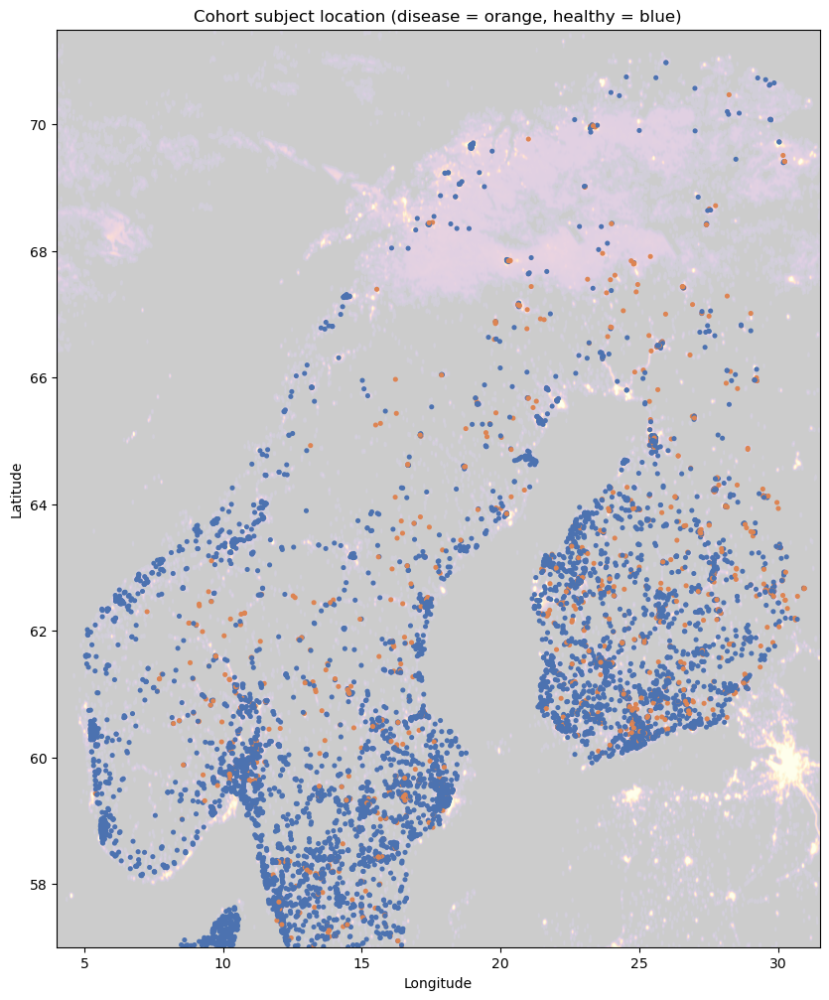

In [4]:
file_path = "summer_school_25/Night_Time_Lights_(NTL)/gDMSP_VIIRS_Monthly_Weighted_2022.tif"
min_lon, min_lat = 4.0, 57.0
max_lon, max_lat = 31.5, 71.5
wsf_extent = [min_lon, max_lon, min_lat, max_lat]

with rasterio.open(file_path) as src:
    # Convert bounding box to raster row/col indices
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    
    # Read only the window
    data = src.read(1, window = window)
    
    # Optional: update the transform for the subset
    transform = src.window_transform(window)

    profile = src.profile  # metadata, CRS, transform, etc.


# Define your custom colors (same as before: muted blue, muted orange)
colors = ["#4C72B0", "#DD8452"]  # healthy = blue, disease = orange

# Create a ListedColormap
cmap = mcolors.ListedColormap(colors)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 12))

# Raster
ax.imshow(data, cmap="inferno", extent=wsf_extent, alpha=0.2)

# Cohort with custom colors
gdf_cohort.plot(
    ax=ax,
    column="disease",        # must be 0/1 or categorical
    cmap=cmap,               # use custom colormap
    markersize=7,
    legend=False
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Cohort subject location (disease = orange, healthy = blue)")
plt.show()

plt.show()

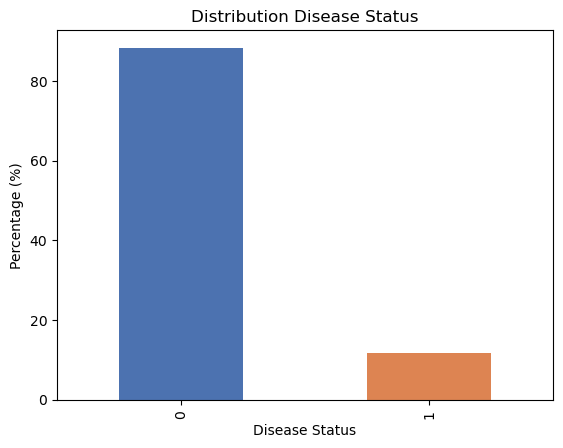

In [5]:
# Compute percentages
percentages = gdf_cohort["disease"].value_counts(normalize=True).sort_index() * 100

# Plot
percentages.plot(kind="bar", color=colors)
plt.rcParams['figure.figsize'] = [3, 4]
plt.xlabel("Disease Status")
plt.ylabel("Percentage (%)")
plt.title("Distribution Disease Status")

plt.show()

/opt/conda/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


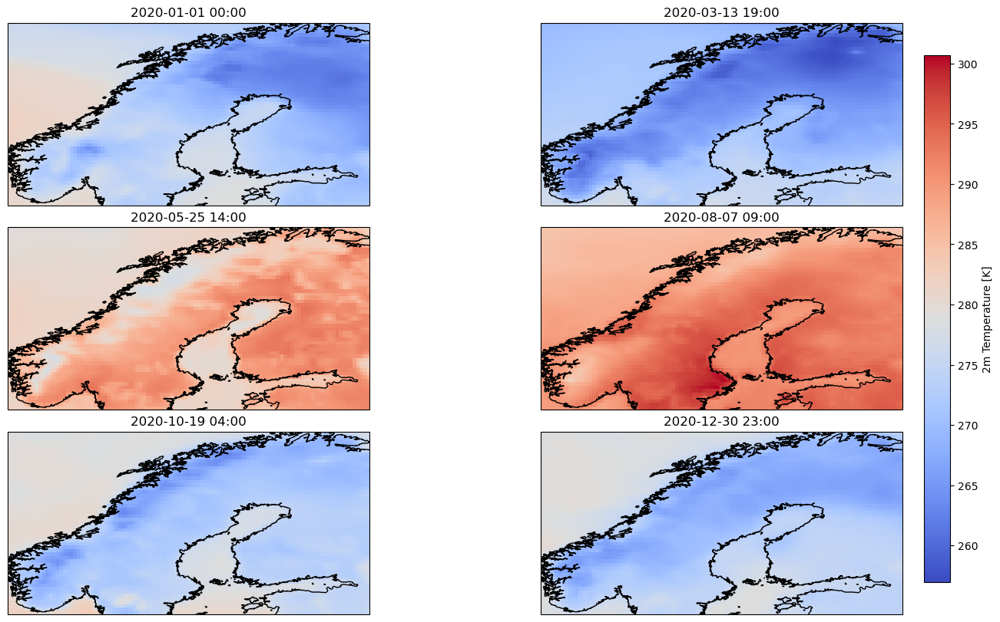

In [6]:


# --- Open dataset ---
file = 'summer_school_25/climate/2m_temperature/2020.nc'
dataset = nc.Dataset(file)

# --- Temperature, lat, lon ---
temp = dataset.variables['t2m'][:]  # shape: (time, lat, lon)
lat = dataset.variables['latitude'][:]
lon = dataset.variables['longitude'][:]

# --- Time conversion ---
time_var = dataset.variables['valid_time']
time_dates = nc.num2date(time_var[:], units=time_var.units)

# --- Select 6 evenly spaced time points ---
time_indices = np.linspace(0, temp.shape[0]-1, 6, dtype=int)

# --- Determine common vmin and vmax across selected times ---
vmin = np.min(temp[time_indices, :, :])
vmax = np.max(temp[time_indices, :, :])

# --- Create figure with constrained_layout ---
fig, axes = plt.subplots(3, 2, figsize=(15, 8),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         constrained_layout=True)

# --- Plot each time step with the same color scale ---
for ax, t_idx in zip(axes.flat, time_indices):
    im = ax.pcolormesh(lon, lat, temp[t_idx, :, :],
                       cmap='coolwarm', shading='auto',
                       vmin=vmin, vmax=vmax)  # <--- fixed color scale
    ax.add_feature(cfeature.COASTLINE)
    ax.set_title(time_dates[t_idx].strftime('%Y-%m-%d %H:%M'))

# --- Shared colorbar ---
cbar = fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.025, pad=0.02)
cbar.set_label('2m Temperature [K]')

### Data aggreagtion on the temporal level

In [25]:
def daily_aggregate(files, var_name, method, new_var_name):
    """
    Compute daily aggregated values (max, min, mean, or sum (spei: only extracts time of interset)) across multiple NetCDF files.

    Parameters
    ----------
    files : list of str
        List of NetCDF file paths.
    var_name : str, optional
        Variable to aggregate.
    method : str, optional
        Aggregation method: "max", "min", "mean", "sum".

    Returns
    -------
    dict
        Dictionary containing 'time', 'latitude', 'longitude', and the aggregated variable.
    """
    if method not in {"max", "min", "mean", "sum"}:
        raise ValueError("method must be one of: 'max', 'min', 'mean', 'sum','spei")

    all_data = []
    all_times = []

    for f in files:
        with nc.Dataset(f) as ds:
            data = ds.variables[var_name][:]
            time_var = ds.variables["valid_time"]
            time_units = getattr(time_var, "units", "seconds since 1970-01-01 00:00:00")
            times = nc.num2date(time_var[:], units=time_units)

            all_data.append(data)
            all_times.append(times)

            # Assume lat/lon are identical across files
            if 'lats' not in locals():
                lats = ds.variables["latitude"][:]
                lons = ds.variables["longitude"][:]

    # Concatenate along time axis
    all_data = np.concatenate(all_data, axis=0)
    all_times = np.concatenate(all_times, axis=0)

    # --- Group by day
    days = np.array([datetime(t.year, t.month, t.day) for t in all_times])
    unique_days = np.unique(days)

    daily_vals = np.empty((len(unique_days), len(lats), len(lons)), dtype=np.float32)

    for i, day in enumerate(unique_days):
        mask = days == day
        if method == "max":
            daily_vals[i] = np.nanmax(all_data[mask], axis=0)
        elif method == "min":
            daily_vals[i] = np.nanmin(all_data[mask], axis=0)
        elif method == "mean":
            daily_vals[i] = np.nanmean(all_data[mask], axis=0)
        elif method == "sum":
            daily_vals[i] = np.nansum(all_data[mask], axis=0)

    # --- Unique dummy name ensures no collision
    dummy_name = f"inmemory_{uuid.uuid4().hex}"
    out_ds = nc.Dataset(dummy_name, mode="w", diskless=True, persist=False, format="NETCDF4")

    # Dimensions
    out_ds.createDimension("valid_time", len(unique_days))
    out_ds.createDimension("latitude", len(lats))
    out_ds.createDimension("longitude", len(lons))

    # Variables
    time_out = out_ds.createVariable("valid_time", "i4", ("valid_time",))
    lat_out = out_ds.createVariable("latitude", "f4", ("latitude",))
    lon_out = out_ds.createVariable("longitude", "f4", ("longitude",))
    var_out = out_ds.createVariable(new_var_name, "f4", ("valid_time", "latitude", "longitude"), zlib=True)

    # Assign values
    lat_out[:] = lats
    lon_out[:] = lons
    time_out[:] = nc.date2num(unique_days, units="days since 1970-01-01 00:00:00", calendar="gregorian")
    time_out.units = "days since 1970-01-01 00:00:00"
    var_out[:] = daily_vals

    # Metadata
    out_ds.description = f"Daily {method} of {new_var_name}"
    out_ds.history = f"Created in-memory on {datetime.utcnow().isoformat()}"

    return out_ds


def subset_by_time(files, var_name, start, end, new_var_name):
    """
    Extract a time subset of a variable from multiple NetCDF files.
    """
    all_data = []
    all_times = []
    lats, lons = None, None

    for f in files:
        with nc.Dataset(f) as ds:
            # force masked arrays to regular ndarrays with NaN
            data = ds.variables[var_name][:].filled(np.nan)

            time_var = ds.variables["valid_time"]
            time_units = getattr(time_var, "units", "days since 1970-01-01 00:00:00")
            times = nc.num2date(
                time_var[:], units=time_units,
                only_use_cftime_datetimes=False,
                only_use_python_datetimes=True
            )

            all_data.append(data)
            all_times.append(times)

            if lats is None:
                lats = ds.variables["latitude"][:]
                lons = ds.variables["longitude"][:]

    # Concatenate
    all_data = np.concatenate(all_data, axis=0)
    all_times = np.concatenate(all_times, axis=0)

    # Use datetime comparison (not np.datetime64!)
    mask = (all_times >= start) & (all_times <= end)
    out_data = all_data[mask]
    out_times = all_times[mask]

    # Create in-memory NetCDF
    dummy_name = f"inmemory_{uuid.uuid4().hex}"
    out_ds = nc.Dataset(dummy_name, mode="w", diskless=True, persist=False, format="NETCDF4")

    out_ds.createDimension("valid_time", len(out_times))
    out_ds.createDimension("latitude", len(lats))
    out_ds.createDimension("longitude", len(lons))

    time_out = out_ds.createVariable("valid_time", "i4", ("valid_time",))
    lat_out = out_ds.createVariable("latitude", "f4", ("latitude",))
    lon_out = out_ds.createVariable("longitude", "f4", ("longitude",))
    var_out = out_ds.createVariable(new_var_name, "f4", ("valid_time", "latitude", "longitude"), zlib=True)

    lat_out[:] = lats
    lon_out[:] = lons
    time_out[:] = nc.date2num(out_times, units="days since 1970-01-01 00:00:00", calendar="gregorian")
    time_out.units = "days since 1970-01-01 00:00:00"
    var_out[:] = out_data

    out_ds.description = f"Subset of {new_var_name} from {start} to {end}"
    out_ds.history = f"Created in-memory on {datetime.utcnow().isoformat()}"

    return out_ds

## Get geospatial data

### netCDF files

- Self-describing format: A NetCDF file stores not only the raw data (e.g., gridded values) but also metadata like variable names, units, dimensions, and attributes inside the file.

- Designed for scientific data: Optimized for multidimensional arrays (e.g., time × latitude × longitude × depth) that are common in climate, weather, and oceanographic data.

- Portable & efficient: Binary format that is platform-independent, meaning the same file can be read on different operating systems without conversion.

- Scalable: Handles very large datasets efficiently with chunking and compression, allowing fast access to subsets of the data without loading the whole file.

- Widely supported: Works with many programming languages and libraries (Python: netCDF4, xarray; R: ncdf4; MATLAB; C; Fortran).

- Standardized conventions: Often follows CF (Climate and Forecast) metadata conventions, making datasets interoperable and easier to understand across scientific communities.

### Climate data

ERA5 is the fifth generation ECMWF reanalysis for the global climate and weather for the past 8 decades. Data is available from 1940 onwards. ERA5 replaces the ERA-Interim reanalysis.

- https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview

In [26]:
geo_data = {}

filelist = [f'summer_school_25/climate/2m_temperature/{y}.nc' for y in range(2015,2025)]
geo_data['t2m_max'] = daily_aggregate(filelist, 't2m', 'max','t2m_max')
geo_data['t2m_min'] = daily_aggregate(filelist, 't2m', 'min','t2m_min')
filelist = [f'summer_school_25/climate/downward_uv_radiation_at_the_surface/{y}.nc' for y in range(2015,2025)]
geo_data['uv_sum'] = daily_aggregate(filelist, 'uvb', 'sum','uv_sum')
filelist = [f'summer_school_25/climate/snowfall/{y}.nc' for y in range(2015,2025)]
geo_data['snowfall'] = daily_aggregate(filelist, 'sf', 'sum','snowfall')
filelist = [f'summer_school_25/climate/total_precipitation/{y}.nc' for y in range(2015,2025)]
geo_data['rain'] = daily_aggregate(filelist, 'tp', 'sum','rain')

### Atmosphere data

EAC4 (ECMWF Atmospheric Composition Reanalysis 4) is the fourth generation ECMWF global reanalysis of atmospheric composition. Reanalysis combines model data with observations from across the world into a globally complete and consistent dataset using a model of the atmosphere based on the laws of physics and chemistry. 

- https://ads.atmosphere.copernicus.eu/datasets/cams-global-reanalysis-eac4?tab=overview

In [27]:
filelist = [f'summer_school_25/atmo/dust_aerosol_optical_depth_550nm/{y}.nc' for y in range(2015,2025)]
geo_data['dust_550nm'] = daily_aggregate(filelist,'duaod550', 'sum','dust_550nm')
filelist = [f'summer_school_25/atmo/organic_matter_aerosol_optical_depth_550nm/{y}.nc' for y in range(2015,2025)]
geo_data['organic_matter_550nm'] = daily_aggregate(filelist,'omaod550', 'sum','organic_matter_550nm')
filelist = [f'summer_school_25/atmo/sulphur_dioxide/{y}.nc' for y in range(2015,2025)]
geo_data['SO2'] = daily_aggregate(filelist,'so2', 'sum','SO2')
filelist = [f'summer_school_25/atmo/total_column_carbon_monoxide/{y}.nc' for y in range(2015,2025)]
geo_data['CO'] = daily_aggregate(filelist,'tcco', 'sum','CO')
filelist = [f'summer_school_25/atmo/total_column_formaldehyde/{y}.nc' for y in range(2015,2025)]
geo_data['CH2O'] = daily_aggregate(filelist,'tchcho', 'sum','CH2O')
filelist = [f'summer_school_25/atmo/total_column_methane/{y}.nc' for y in range(2015,2025)]
geo_data['CH4'] = daily_aggregate(filelist,'tc_ch4', 'sum','CH4')
filelist = [f'summer_school_25/atmo/total_column_ozone/{y}.nc' for y in range(2015,2025)]
geo_data['O3'] = daily_aggregate(filelist,'gtco3', 'sum','O3')

### Drought

The SPEI is a multiscalar drought index based on climatic data. It can be used for determining the onset, duration and magnitude of drought conditions with respect to normal conditions in a variety of natural and managed systems such as crops, ecosystems, rivers, water resources, etc.

https://spei.csic.es/

In [28]:
file= ['summer_school_25/drought/18.nc']

geo_data['spei'] = subset_by_time(file,'spei',pd.Timestamp("2014-12-31"),pd.Timestamp("2025-1-1"),'spei')

## geoTiff

- GeoTIFF = TIFF + georeferencing: It’s a standard TIFF image format with embedded metadata that ties pixel locations to real-world coordinates (CRS, projection, geotransform).

- Raster data storage: Used to store gridded data such as satellite imagery, elevation models (DEMs), land cover, climate grids, etc.

- Self-contained: The georeferencing information (coordinate system, affine transform, projection) is stored in the same file, so no sidecar files (like .tfw) are strictly required.

- Supports multiple bands: Can contain single-band rasters (e.g., elevation) or multi-band rasters (e.g., RGB/NIR imagery).

- Efficient access: Supports internal tiling and overviews (pyramids), which allow fast reading of subsets or lower-resolution versions without loading the whole dataset.

- Widely supported: Read and written by almost all GIS and remote sensing software (QGIS, ArcGIS, GDAL, rasterio, etc.).

In [29]:
# geoTiffs may be too large to load into memory, so we read only the needed window
min_lon, min_lat = 4.0, 57.0
max_lon, max_lat = 31.5, 71.5

### Night Time Lights

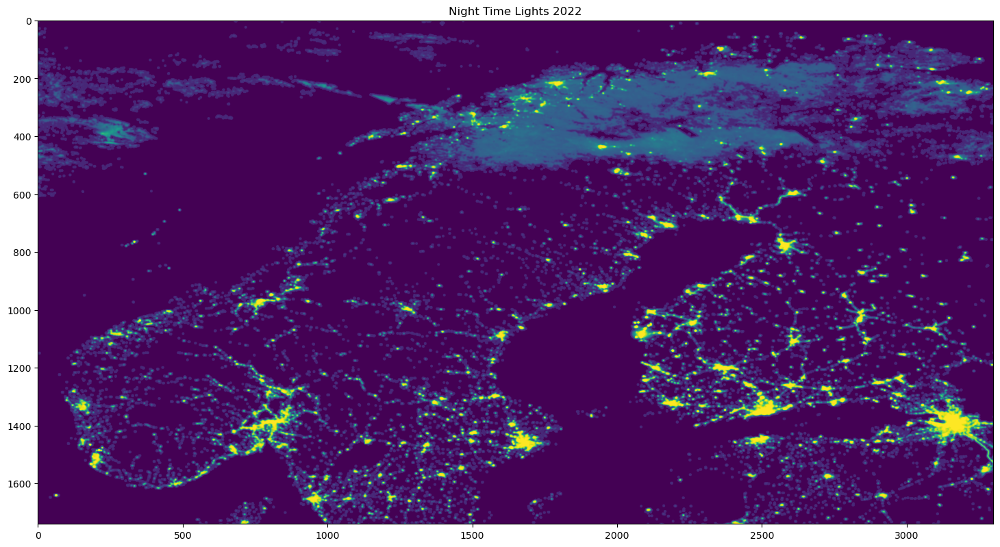

In [13]:
file_path = "summer_school_25/Night_Time_Lights_(NTL)/gDMSP_VIIRS_Monthly_Weighted_2022.tif"

with rasterio.open(file_path) as src:
    # Convert bounding box to raster row/col indices
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    
    # Read only the window
    ntl = src.read(1, window=window)
    
    # Optional: update the transform for the subset
    transform_ntl = src.window_transform(window)

    profile = src.profile  # metadata, CRS, transform, etc.

plt.figure(figsize=(18, 10))  # width=12, height=8 inches
plt.imshow(ntl, cmap='viridis', origin='upper')
#plt.colorbar(label='Value')
plt.title("Night Time Lights 2022")
plt.show()

### Tree Cover

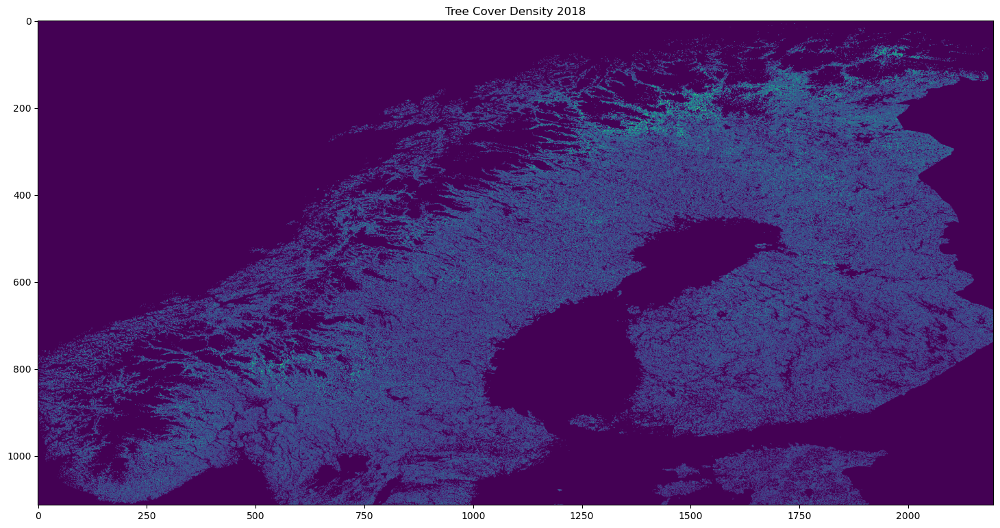

In [14]:
file_path = "summer_school_25/treeCover/HRL_TreeCoverDensity_2018.tif"

with rasterio.open(file_path) as src:
    # Convert bounding box to raster row/col indices
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    
    # Read only the window
    treeCover = src.read(1)#, window=window)
    
    # Optional: update the transform for the subset
    transform = src.window_transform(window)

    profile = src.profile  # metadata, CRS, transform, etc.

data_small = treeCover[::20, ::20]
plt.figure(figsize=(18, 10))  # width=12, height=8 inches
plt.imshow(data_small, cmap='viridis', origin='upper')
#plt.colorbar(label='Value')
plt.title("Tree Cover Density 2018")
plt.show()

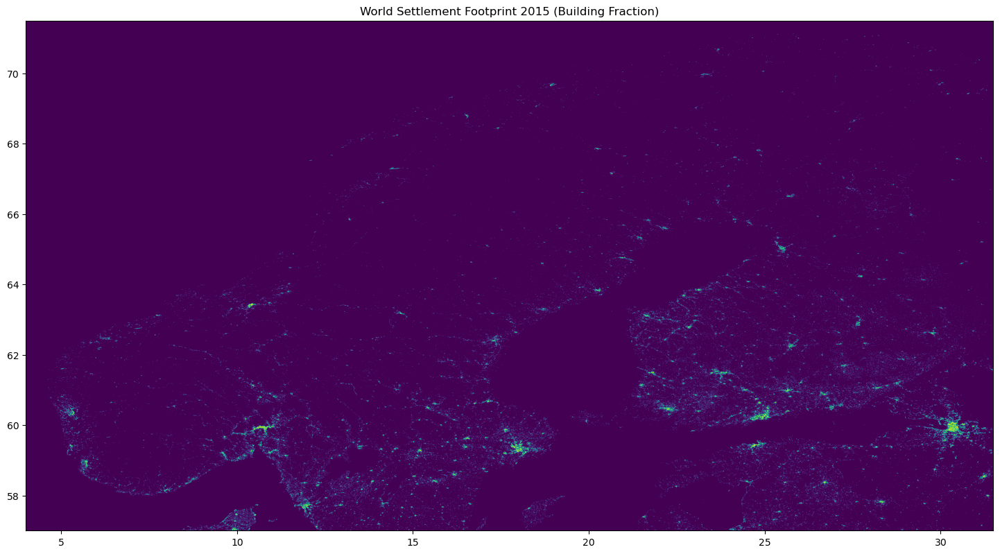

In [15]:
file_path = "summer_school_25/wsf/WSF3D_V02_BuildingFraction.tif"

with rasterio.open(file_path) as src:
    # Convert bounding box to raster row/col indices
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    
    # Read only the window
    wsf = np.abs(255-src.read(1, window=window))/255
    
    # Optional: update the transform for the subset
    transform = src.window_transform(window)
    
    profile = src.profile  # metadata, CRS, transform, etc.

wsf_extent = [min_lon, max_lon, min_lat, max_lat]

data_small = wsf[::5, ::5]
plt.figure(figsize=(18, 10))  # width=12, height=8 inches
plt.imshow(data_small, cmap='viridis', extent=wsf_extent, origin='upper')
#plt.colorbar(label='Value')
plt.title("World Settlement Footprint 2015 (Building Fraction)")
plt.show()

## Linking

### geoTiffs

Straight forward as temporal aspects can be ignored for WSF and Night Time lights.

In [30]:
xs = gdf_cohort.geometry.x.to_numpy()
ys = gdf_cohort.geometry.y.to_numpy()

# Open once
with rasterio.open("summer_school_25/wsf/WSF3D_V02_BuildingFraction.tif") as src:
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    raster = np.abs(255-src.read(1, window=window))/255         # read raster into memory
    transform = src.window_transform(window)    # affine transform for pixel->geo

# Convert all coords to raster row/col
shape = raster.shape
rows, cols = rasterio.transform.rowcol(transform, xs, ys)
rows = np.clip(rows, 0, shape[0]-1)
cols = np.clip(cols, 0, shape[1]-1)
gdf_cohort['wsf'] = raster[rows, cols]

with rasterio.open("summer_school_25/Night_Time_Lights_(NTL)/gDMSP_VIIRS_Monthly_Weighted_2022.tif") as src:
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    raster = src.read(1, window=window)      # read raster into memory
    transform = src.window_transform(window)    # affine transform for pixel->geo


# Convert all coords to raster row/col
shape = raster.shape
rows, cols = rasterio.transform.rowcol(transform, xs, ys)
rows = np.clip(rows, 0, shape[0]-1)
cols = np.clip(cols, 0, shape[1]-1)
gdf_cohort['ntl'] = raster[rows, cols]

For Tree Cover temporal aspects can be ignored as well but we will take the neighborhood into account.

In [31]:
def circular_mask(radius):
    """Create a circular boolean mask with given pixel radius."""
    y, x = np.ogrid[-radius:radius+1, -radius:radius+1]
    return x**2 + y**2 <= radius**2

# Example radius in pixels (e.g., 3px ~ depending on raster resolution)
radius = 15
circle = circular_mask(radius)

# Open raster
with rasterio.open("summer_school_25/treeCover/HRL_TreeCoverDensity_2018.tif") as src:
    window = from_bounds(min_lon, min_lat, max_lon, max_lat, transform=src.transform)
    raster = src.read(1, window=window)
    transform = src.window_transform(window)

shape = raster.shape
rows, cols = rasterio.transform.rowcol(transform, xs, ys)

# Clip to raster extent
rows = np.clip(rows, 0, shape[0]-1)
cols = np.clip(cols, 0, shape[1]-1)

# Convert all coords to raster row/col
gdf_cohort['greeness'] = raster[rows, cols]

means = []
for r, c in zip(rows, cols):
    # Define local window around the point
    r0, r1 = r - radius, r + radius + 1
    c0, c1 = c - radius, c + radius + 1

    # Clip to raster boundaries
    r0, r1 = max(r0, 0), min(r1, shape[0])
    c0, c1 = max(c0, 0), min(c1, shape[1])

    patch = raster[r0:r1, c0:c1]

    # Match circular mask to actual patch size
    mask = circle[
        (r0-r+radius):(r1-r+radius),
        (c0-c+radius):(c1-c+radius)
    ]

    # Apply mask and compute mean
    vals = patch[mask]
    vals = vals[vals != src.nodata] if src.nodata is not None else vals
    means.append(np.nan if vals.size == 0 else vals.mean())

gdf_cohort['greenness_neighborhod'] = np.array(means)

### Linking netCDF files 

Have an additional temporal dimension, so we need to subset by time as well

In [32]:
def point_netcdf_summary(gdf_subject, variable_name, ds, method, offset_years=1):
    # Extract coordinates from dataset
    lats = ds.variables["latitude"][:]
    lons = ds.variables["longitude"][:]

    # Precompute coordinate arrays for gdf
    xs = gdf_subject.geometry.x.to_numpy()
    ys = gdf_subject.geometry.y.to_numpy()

    # Map each point to nearest grid cell once
    lat_idx = np.abs(ys[:, None] - lats[None, :]).argmin(axis=1)
    lon_idx = np.abs(xs[:, None] - lons[None, :]).argmin(axis=1)

    # Convert valid_time to datetime once
    time_var = ds.variables["valid_time"]
    time_units = getattr(time_var, "units", "days since 1970-01-01 00:00:00")
    times = nc.num2date(time_var[:], units=time_units)

    results = []

    for i, row in enumerate(gdf_subject.itertuples(index=False)):
        # Time window
        end_time = row.date
        start_time = row.date - pd.DateOffset(years=offset_years)
        mask = (times >= start_time) & (times <= end_time)

        # Extract values only for time window + nearest grid point
        arr = ds.variables[variable_name][mask, lat_idx[i], lon_idx[i]]

        # Interpolate if NaNs
        if np.any(np.isnan(arr)):
            x = np.arange(len(arr))
            valid = ~np.isnan(arr)
            if valid.any():
                arr[~valid] = np.interp(x[~valid], x[valid], arr[valid])

        # Aggregate
        if method == "mean":
            val = arr.mean()
        elif method == "max":
            val = arr.max()
        elif method == "min":
            val = arr.min()
        elif method == "sum":
            val = arr.sum()
        else:
            raise ValueError("method must be one of: 'max', 'min', 'mean', 'sum'")

        results.append(val)
        # print % done every 100
        if (i+1) % 100 == 0:
            print(f"Processed {i+1}/{len(gdf_subject)} points ({variable_name})")

    return np.array(results)

For the climate and atmo data and spei, we use 1 year offset years

There is a additional aggragation step so that the sum of the values over the offset year are summed (the function used can also do mean, max or min)

The linking can take several minutes, you can skip this step and go to the cell and load already linked data.

In [33]:
# use point_netcdf_summary to do aggreagting linking using the year before assessment 

for variable_name, ds in geo_data.items():
    print(f"Processing {variable_name}...")
    gdf_cohort[variable_name] = point_netcdf_summary(gdf_cohort, variable_name, ds, 'sum', offset_years = 1)

# Save to geopandas dataframe file
gdf_cohort.to_file("simulated_data_enriched.gpkg", driver="GPKG")


Processing t2m_max...
Processed 100/10000 points (t2m_max)
Processed 200/10000 points (t2m_max)
Processed 300/10000 points (t2m_max)
Processed 400/10000 points (t2m_max)
Processed 500/10000 points (t2m_max)
Processed 600/10000 points (t2m_max)
Processed 700/10000 points (t2m_max)
Processed 800/10000 points (t2m_max)
Processed 900/10000 points (t2m_max)
Processed 1000/10000 points (t2m_max)
Processed 1100/10000 points (t2m_max)
Processed 1200/10000 points (t2m_max)
Processed 1300/10000 points (t2m_max)
Processed 1400/10000 points (t2m_max)
Processed 1500/10000 points (t2m_max)
Processed 1600/10000 points (t2m_max)
Processed 1700/10000 points (t2m_max)
Processed 1800/10000 points (t2m_max)
Processed 1900/10000 points (t2m_max)
Processed 2000/10000 points (t2m_max)
Processed 2100/10000 points (t2m_max)
Processed 2200/10000 points (t2m_max)
Processed 2300/10000 points (t2m_max)
Processed 2400/10000 points (t2m_max)
Processed 2500/10000 points (t2m_max)
Processed 2600/10000 points (t2m_max)

In [34]:
# Load the geopandas dataframe file
gdf_cohort = gpd.read_file("simulated_data_enriched.gpkg")

# Check the type
gdf_cohort = gdf_cohort.dropna()
gdf_cohort

,id,disease,date,wsf,ntl,greeness,greenness_neighborhod,t2m_max,t2m_min,uv_sum,...,rain,dust_550nm,organic_matter_550nm,SO2,CO,CH2O,CH4,O3,spei,geometry
0,1,0,2021-08-16,0.941176,8,31,47.496474,101548.500000,100721.742188,399057984.0,...,2.370799,6.362047,133.692200,2.856388e-06,2.498162,0.003312,29.246363,21.078430,13.747499,POINT (5.33506 59.96828)
1,2,1,2019-09-13,0.976471,63,0,24.921016,101837.679688,99469.343750,398871040.0,...,0.791592,16.429581,170.691528,9.165045e-07,2.426543,0.003863,29.176687,21.376888,-16.589878,POINT (14.49572 59.32894)
2,3,0,2018-08-19,0.878431,52,69,34.716502,100681.914062,98318.421875,360296896.0,...,0.692942,7.519097,132.488495,7.651112e-07,2.514020,0.003426,29.094528,20.994087,8.002205,POINT (26.34983 63.18128)
3,4,1,2024-11-15,0.941176,63,46,45.770099,101978.578125,99209.335938,383193696.0,...,0.622229,11.791300,119.677597,5.374840e-07,2.593825,0.003647,29.641663,21.664032,0.723508,POINT (17.17517 60.67372)
4,5,0,2023-07-30,0.792157,63,64,59.196051,101617.390625,98951.828125,391664864.0,...,1.147548,3.512849,121.664589,6.202826e-06,2.333889,0.005009,28.816761,20.892023,-10.039798,POINT (10.72506 59.91228)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,1,2020-01-28,0.917647,63,0,35.974612,101397.445312,99098.781250,366078080.0,...,0.750643,9.430462,184.225510,1.319932e-06,2.431864,0.003482,29.136658,21.066813,-18.526562,POINT (23.60894 61.5005)
9996,9997,0,2018-05-21,0.964706,63,0,0.000000,101483.125000,99189.843750,403694720.0,...,1.266530,7.726542,128.288788,9.751539e-06,2.415529,0.004580,28.342896,21.265274,7.953323,POINT (9.65483 59.15472)
9997,9998,0,2024-12-19,0.996078,32,52,61.083216,100775.765625,98316.343750,388473856.0,...,1.389792,6.688900,96.229935,1.014594e-06,2.275666,0.002856,26.917454,21.609640,0.000000,POINT (8.00672 59.44639)
9998,9999,0,2022-11-30,0.964706,33,0,0.000000,102085.171875,99184.585938,386834240.0,...,0.646557,8.694422,117.530411,8.544392e-07,2.368937,0.003756,29.558678,21.197411,-17.643120,POINT (16.41839 59.7295)


## Analysis

Here’s a set of concise, slide-ready bullet points on sns.pairplot (from Seaborn) for a scientific or data-focused presentation:

- Creates a matrix of scatterplots for all pairs of numerical variables in a dataset.

- Allows visualization of relationships and correlations between variables.

- Supports hue parameter to color points by a categorical variable.

- Can display histograms or KDE plots on the diagonal to show distributions.

- Useful for exploratory data analysis and detecting patterns or outliers.

- Highly customizable with markers, palette, and plot kind options.

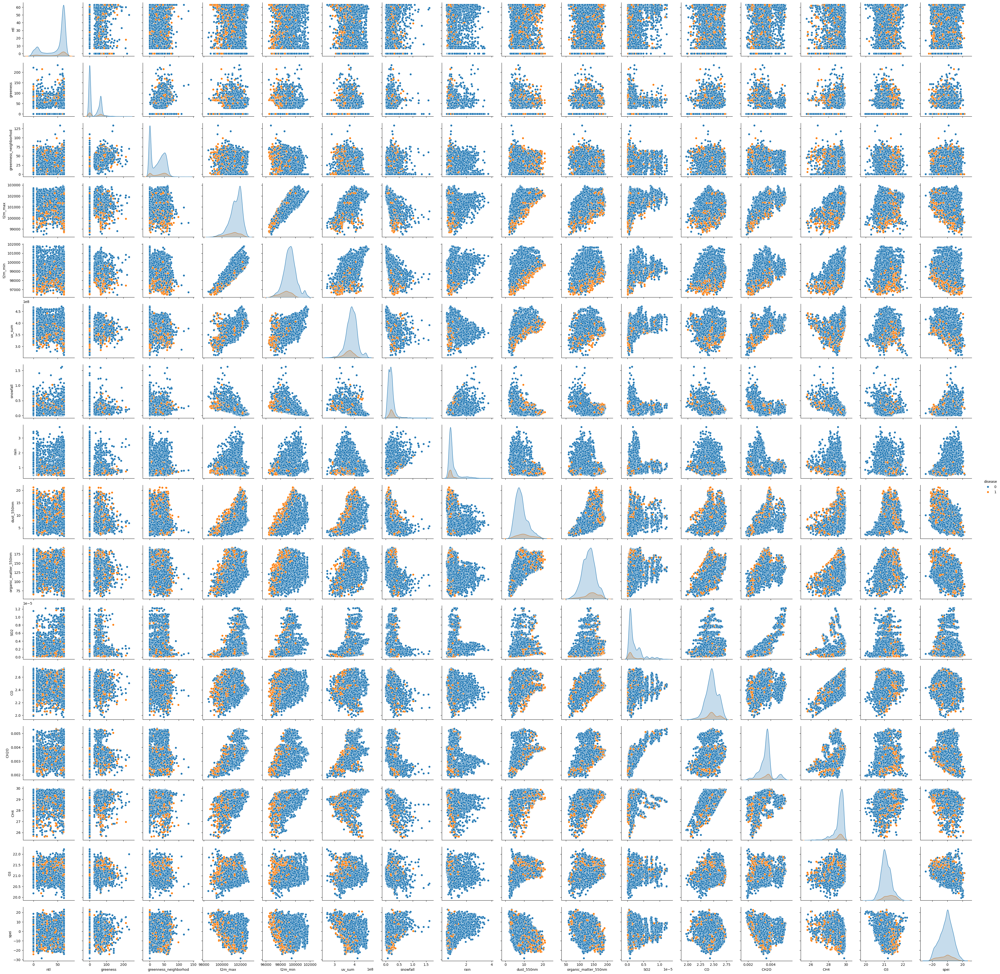

In [41]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# gepsaptial keys:
geo_keys = gdf_cohort.keys()[4:-1]

# pairplot of all keys
sns.pairplot(gdf_cohort, hue='disease', vars=geo_keys, diag_kind='kde')
plt.show()

In [39]:
geo_keys

Index(['ntl', 'greeness', 'greenness_neighborhod', 't2m_max', 't2m_min',
       'uv_sum', 'snowfall', 'rain', 'dust_550nm', 'organic_matter_550nm',
       'SO2', 'CO', 'CH2O', 'CH4', 'O3', 'spei'],
      dtype='object')

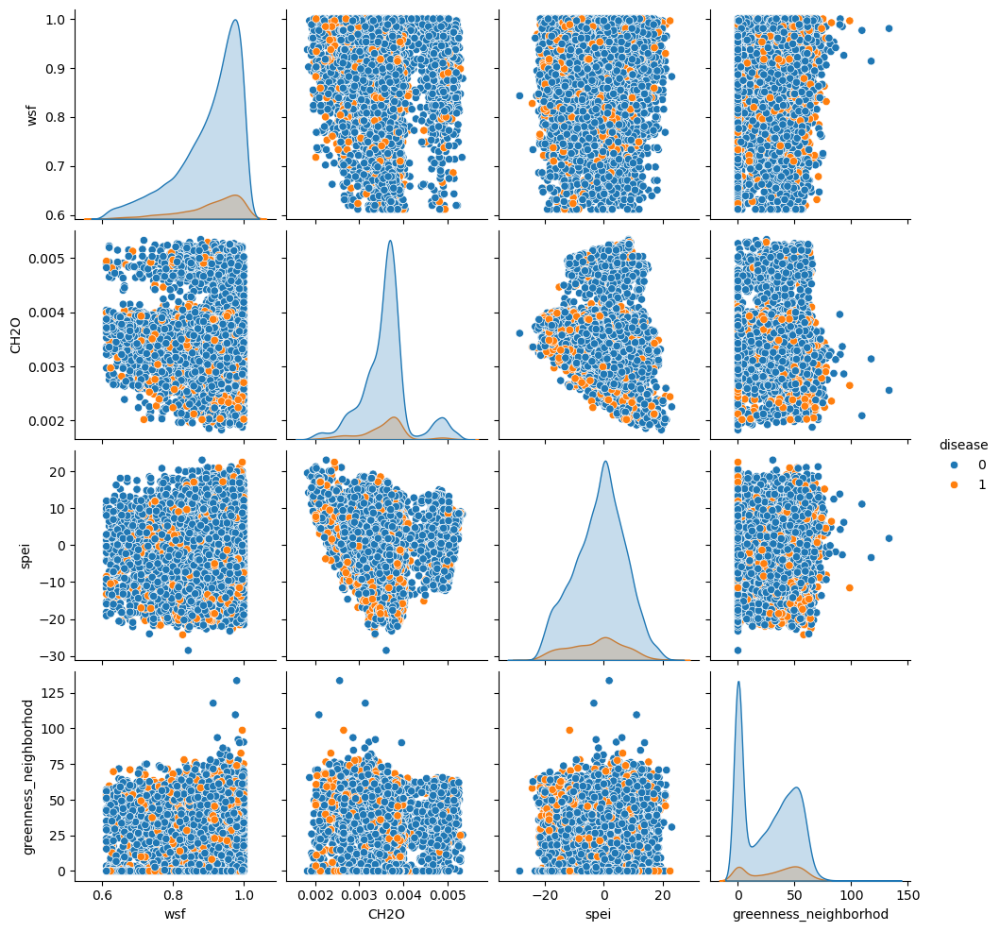

In [44]:
# pairplot of all keys
sns.pairplot(gdf_cohort, hue='disease', vars=['wsf','CH2O','spei','greenness_neighborhod'], diag_kind='kde')
plt.show()

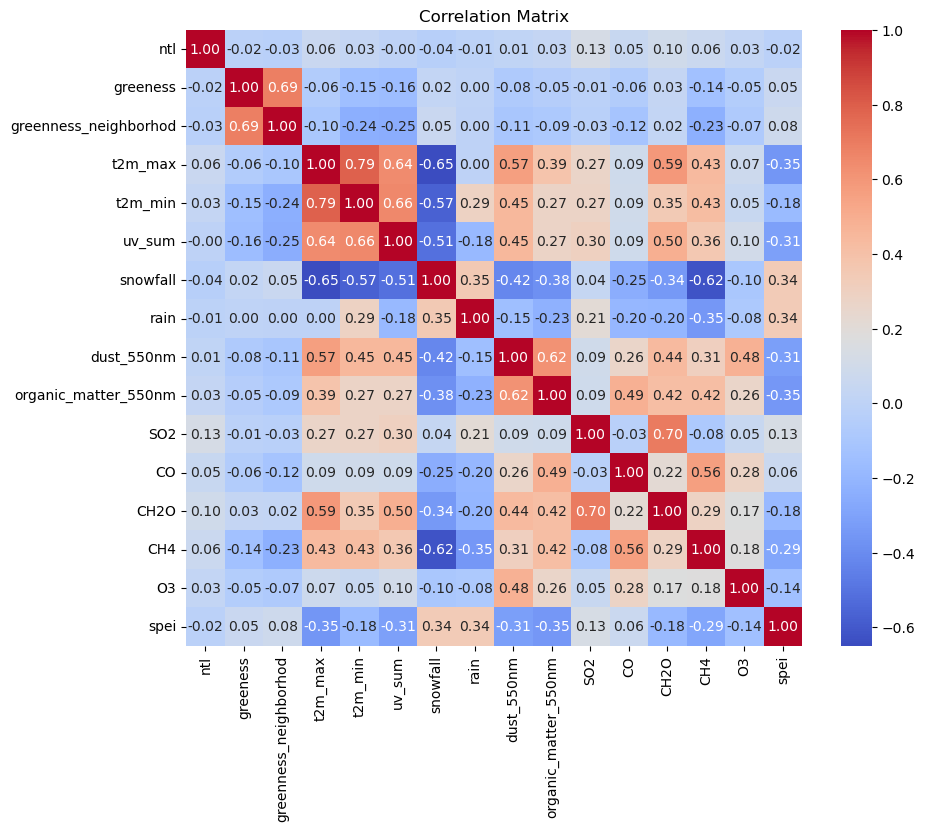

In [45]:
# correlation matrix

corr = gdf_cohort[geo_keys].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Matrix')
plt.show()

## Data preperation

- Remove incomplete data: Drop rows in the GeoDataFrame with missing values in key geographic columns.

- Define features and target:

    - Features (X) = selected geographic variables

    - Target (y) = disease outcome (converted to integer)

- Split dataset: Separate into training (70%) and testing (30%) sets for model evaluation.

- Scale features: Standardize feature values using StandardScaler to improve model performance.

- Apply scaling consistently: Fit scaler on training data and transform both training and test sets.

In [46]:
# strip gdf from columns that contaont nan values
gdf_nonan = gdf_cohort.dropna(subset=geo_keys)

# Convert selected columns to float
gdf_nonan[geo_keys] = gdf_nonan[geo_keys].astype(float)

# Features and target
X = gdf_nonan[geo_keys]
y = gdf_nonan['disease'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Random Forest (non-linear relationships)

- Random Forest automatically handles non-linear effects and interactions.

- Top features in feature_importances_ are potential causes or confounders.

In [47]:
rf = RandomForestClassifier(n_estimators=500, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

# Feature importance
importance_rf = pd.DataFrame({
    "feature": geo_keys,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

print('------------------------------------------------------------')
print(importance_rf)

              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2664
           1       0.55      0.32      0.41       336

    accuracy                           0.89      3000
   macro avg       0.73      0.65      0.67      3000
weighted avg       0.88      0.89      0.88      3000

ROC-AUC: 0.9037424701487201
------------------------------------------------------------
                  feature  importance
8              dust_550nm    0.134246
4                 t2m_min    0.124723
14                     O3    0.088250
3                 t2m_max    0.075051
9    organic_matter_550nm    0.072366
5                  uv_sum    0.062298
7                    rain    0.058583
12                   CH2O    0.057738
6                snowfall    0.057145
15                   spei    0.057095
13                    CH4    0.053551
11                     CO    0.051771
2   greenness_neighborhod    0.038098
0                     ntl    0.027008
1             

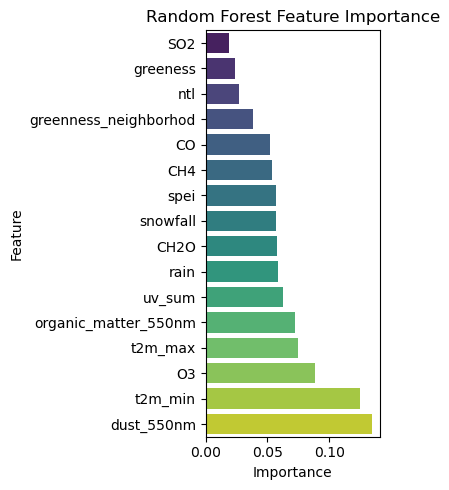

In [48]:
# Sort by importance
importance_df = importance_rf.sort_values("importance", ascending=True)

plt.figure(figsize=(4,5))
# Use hue to avoid the warning, legend=False since we don't need a legend
sns.barplot(x="importance", y="feature", data=importance_df, hue="feature", palette="viridis", dodge=False, legend=False)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Permutation Importance (Mean Decrease in Accuracy, MDA)

Randomly shuffle one feature and see how much the model’s accuracy drops.

More reliable, especially when features are correlated:

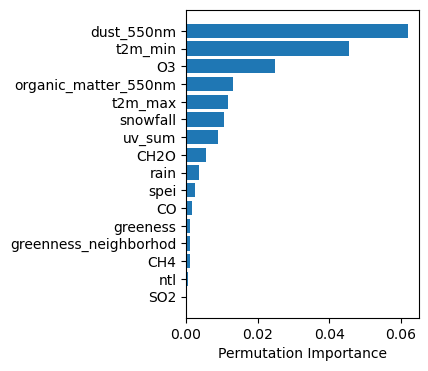

In [49]:
r = permutation_importance(rf, X, y, n_repeats=30, random_state=42)
sorted_idx = r.importances_mean.argsort()

plt.barh(X.columns[sorted_idx], r.importances_mean[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [ ]:
X_train[geo_keys]

### Local Explanations (impact on individual predictions)

Global importance tells you which variables matter on average, but you might also want to know how they impact predictions for specific cases.

Here you’d use post-hoc explainability tools:

Partial Dependence Plots (PDPs):
Show the average effect of a variable on predictions.
Example: how does disease probability change as temperature increases?

### Partial dependence plots (PDP)

Shows how each feature affects disease probability, holding others constant:

['SO2', 'ntl', 'greenness_neighborhod', 'greeness', 'CO', 'spei', 'rain', 'CH2O', 'uv_sum', 'snowfall', 't2m_max', 'organic_matter_550nm', 'O3', 't2m_min', 'dust_550nm']


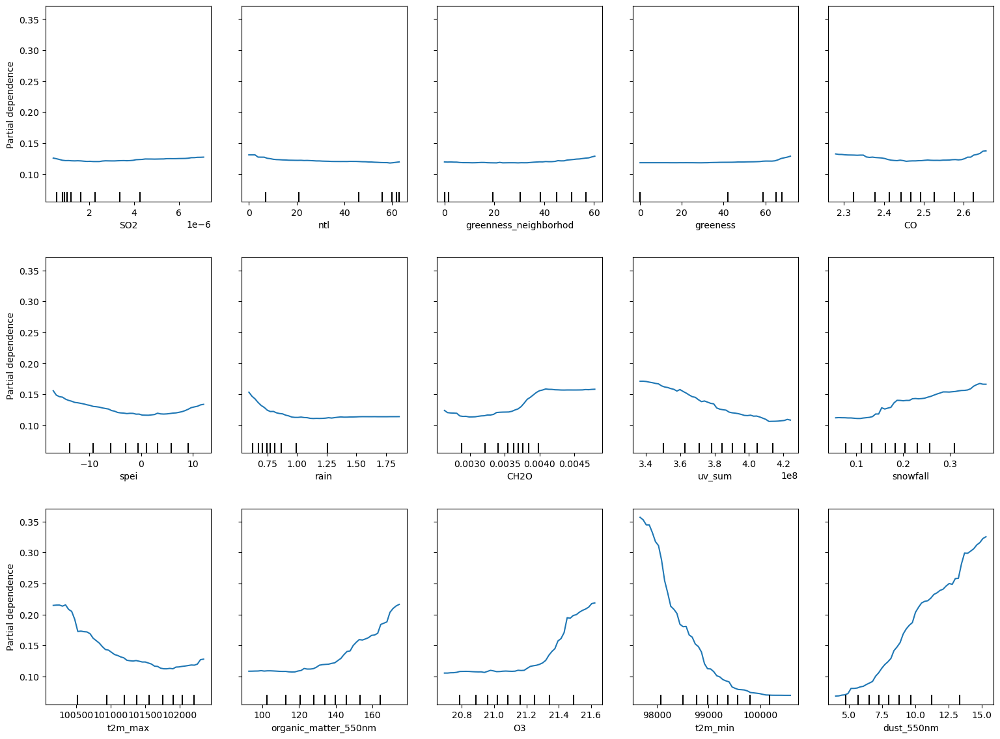

In [54]:
features_to_plot = [geo_keys[i] for i in sorted_idx]  # make a sublist
features_to_plot.pop(2)
# Create a wider figure
fig, ax = plt.subplots(nrows=3, ncols=5, figsize=(16, 12))  # 16 inches wide, 12 inches tall

PartialDependenceDisplay.from_estimator(
    rf, 
    X_train, 
    features=features_to_plot,#[::-1],
    kind="average",
    grid_resolution=50,
    ax=ax  # pass our customized axes
)

plt.tight_layout(pad=3.0)  # add extra padding between subplots
plt.show()



## SHAP (SHapley Additive exPlanations):

Assigns each feature a contribution for each individual prediction.

Great for understanding both global & local importance.

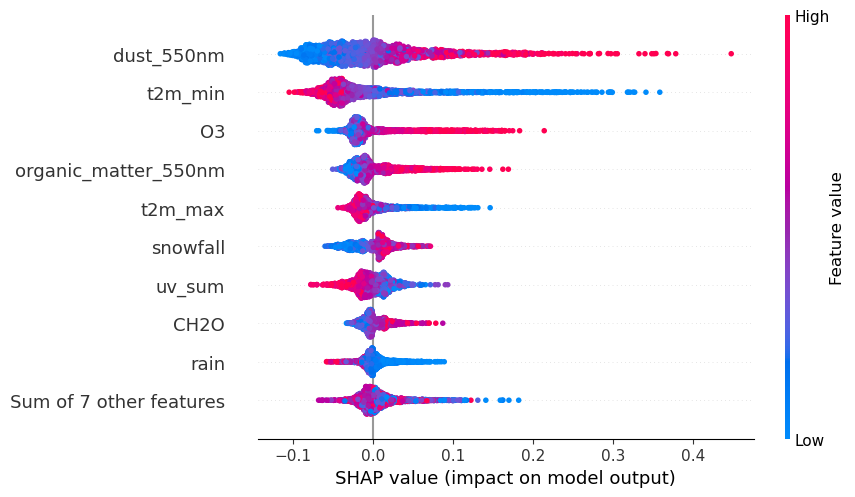

In [55]:
explainer = shap.TreeExplainer(rf)
explanation = explainer(X_test)

shap_values = explanation.values

shap.plots.beeswarm(explanation[:-100,:,1])

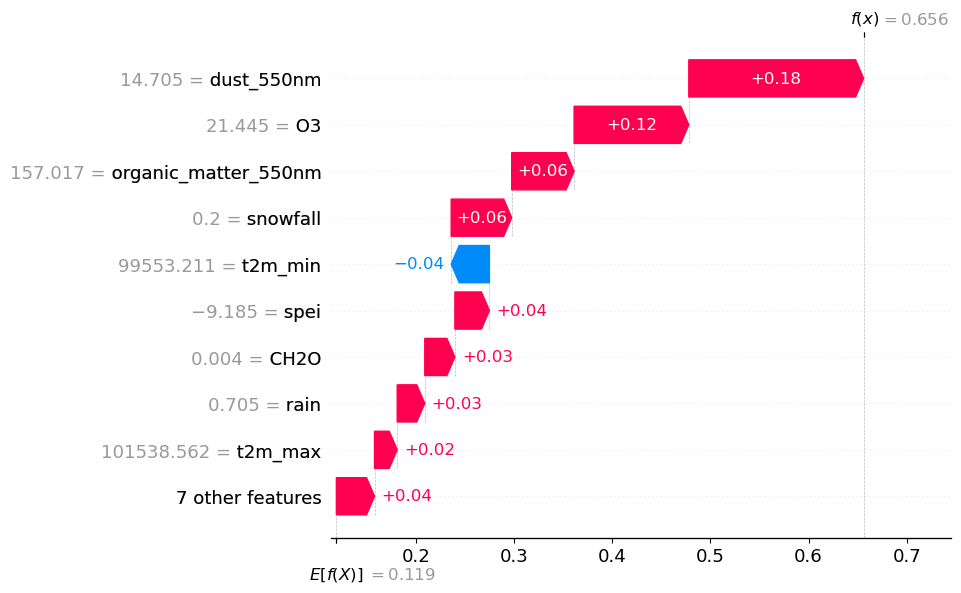

In [56]:
shap.plots.waterfall(explanation[2,:,1])

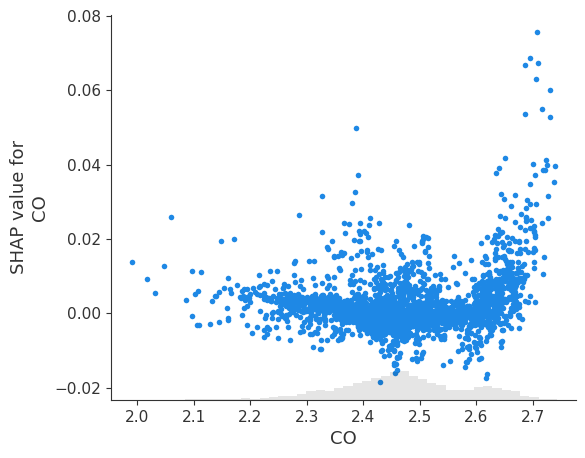

In [57]:
shap.plots.scatter(explanation[:, "CO", 1])